# 02 Per image: do CNN and SNN break at the same severity?

No features or images are exported, so each image is described by its **behaviour profile**: right/wrong for both models in all 15 conditions plus agreement (45 binary values). The projection groups images that behave alike; the *breaking-severity* view asks per image and corruption up to which severity each model is still right. Tests H5, H6.

Caveat (Lecture 03): UMAP cluster sizes and gaps are not meaningful; parameters are printed.

In [1]:
%matplotlib inline
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
# shared setup for all three notebooks, so not every name is used in each
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # noqa: F401

from aiv.load import CORRUPTIONS, GROUPS, NAMES, OUTCOMES, SEVERITIES, paired  # noqa: F401
from aiv.load import GROUP as GROUP_OF, table, wordnet_distance  # noqa: F401
from aiv.stats import paired_diff, wilson  # noqa: F401

RUN = "card"                      # "card" = AKD1000 run, "sim" = software simulator run
W = paired(RUN)
COND = [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"run = {RUN} | {W.image_id.nunique()} images x {len(COND)} conditions = {len(W):,} rows | "
      f"{W.label.nunique()} classes in {len(GROUPS)} WordNet groups")

run = card | 2000 images x 15 conditions = 30,000 rows | 1000 classes in 14 WordNet groups


## Breaking severity, paired per image
For each image and corruption: the highest severity at which the model is still right (0 = already wrong at severity 1). The diagonal = both models break at the same step. Only images that at least one model gets right at severity 1.

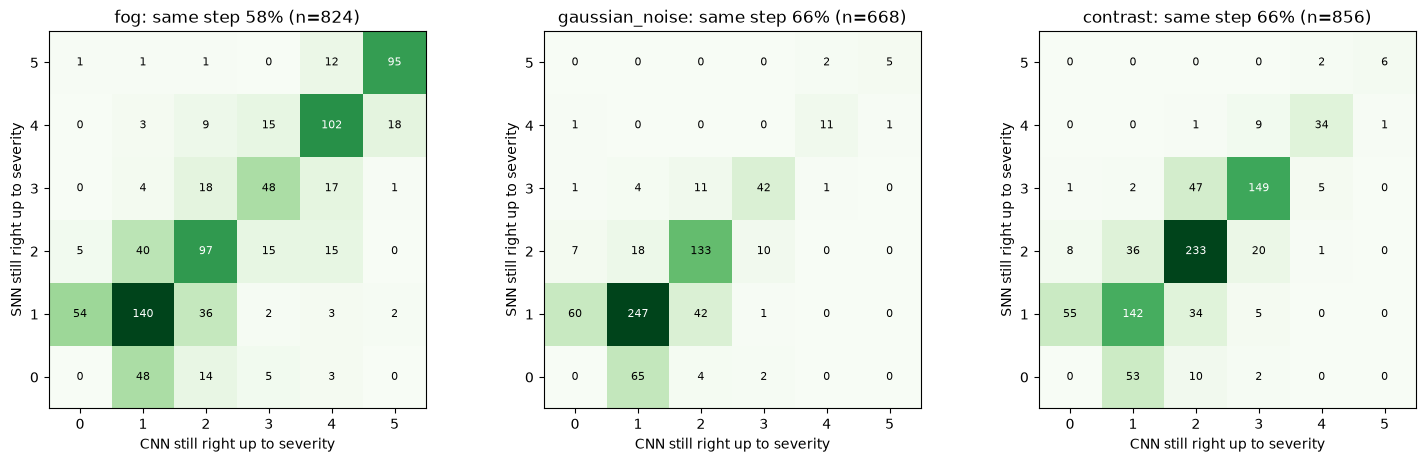

In [3]:
def last_ok(d, m):
    """Per image: how many severities in a row (from 1) the model is right, and whether it is
    right again after a miss (non-monotonic)."""
    piv = d.pivot_table(index="image_id", columns="severity", values=f"{m}_ok", aggfunc="first")
    ok = piv[SEVERITIES].values.astype(bool)
    run = np.cumprod(ok, axis=1).sum(1)              # 0..5: still right up to this severity
    recover = (np.diff(ok.astype(int), axis=1) > 0).any(1)
    return pd.Series(run, index=piv.index), pd.Series(recover, index=piv.index)

BR = []
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, corr in zip(axs, CORRUPTIONS):
    d = W[W.corruption == corr]
    bc, rc = last_ok(d, "cnn")
    bs, rs = last_ok(d, "snn")
    b = pd.DataFrame({"cnn": bc, "snn": bs, "recover_cnn": rc, "recover_snn": rs}).assign(corruption=corr)
    BR.append(b.reset_index())
    b = b[(b.cnn > 0) | (b.snn > 0)]
    M = pd.crosstab(b.snn, b.cnn).reindex(index=range(6), columns=range(6), fill_value=0)
    im = ax.imshow(M.values, cmap="Greens", origin="lower")
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="w" if v > M.values.max() * .6 else "k")
    diag = np.trace(M.values) / M.values.sum()
    ax.set_title(f"{corr}: same step {diag:.0%} (n={M.values.sum()})")
    ax.set_xlabel("CNN still right up to severity")
    ax.set_ylabel("SNN still right up to severity")
plt.tight_layout()
plt.show()
BR = pd.concat(BR, ignore_index=True)

Is the off-diagonal mass symmetric? A paired sign test per corruption: images where the SNN lasts longer vs the CNN lasts longer.

In [4]:
from scipy.stats import binomtest
rows = []
for corr, b in BR.groupby("corruption", sort=False):
    b = b[(b.cnn > 0) | (b.snn > 0)]
    s_longer, c_longer = (b.snn > b.cnn).sum(), (b.cnn > b.snn).sum()
    p = binomtest(s_longer, s_longer + c_longer).pvalue
    rows.append((corr, len(b), (b.snn == b.cnn).mean(), s_longer, c_longer, p,
                 b.recover_cnn.mean(), b.recover_snn.mean()))
pd.DataFrame(rows, columns=["corruption", "n", "same step", "SNN lasts longer", "CNN lasts longer",
                            "sign-test p", "CNN right again after a miss", "SNN right again after a miss"]).round(3)

,corruption,n,same step,SNN lasts longer,CNN lasts longer,sign-test p,CNN right again after a miss,SNN right again after a miss
0,fog,824,0.585,163,179,0.417,0.096,0.131
1,gaussian_noise,668,0.656,104,126,0.166,0.028,0.021
2,contrast,856,0.659,161,131,0.090,0.023,0.029


## Behaviour-profile projection
UMAP (Hamming distance) of the 45-value profiles. Colour = how many of the 15 conditions the CNN gets right, and = WordNet group.

UMAP {'n_neighbors': 30, 'min_dist': 0.2, 'metric': 'hamming', 'random_state': 0} | images: 2000 | dims: 45


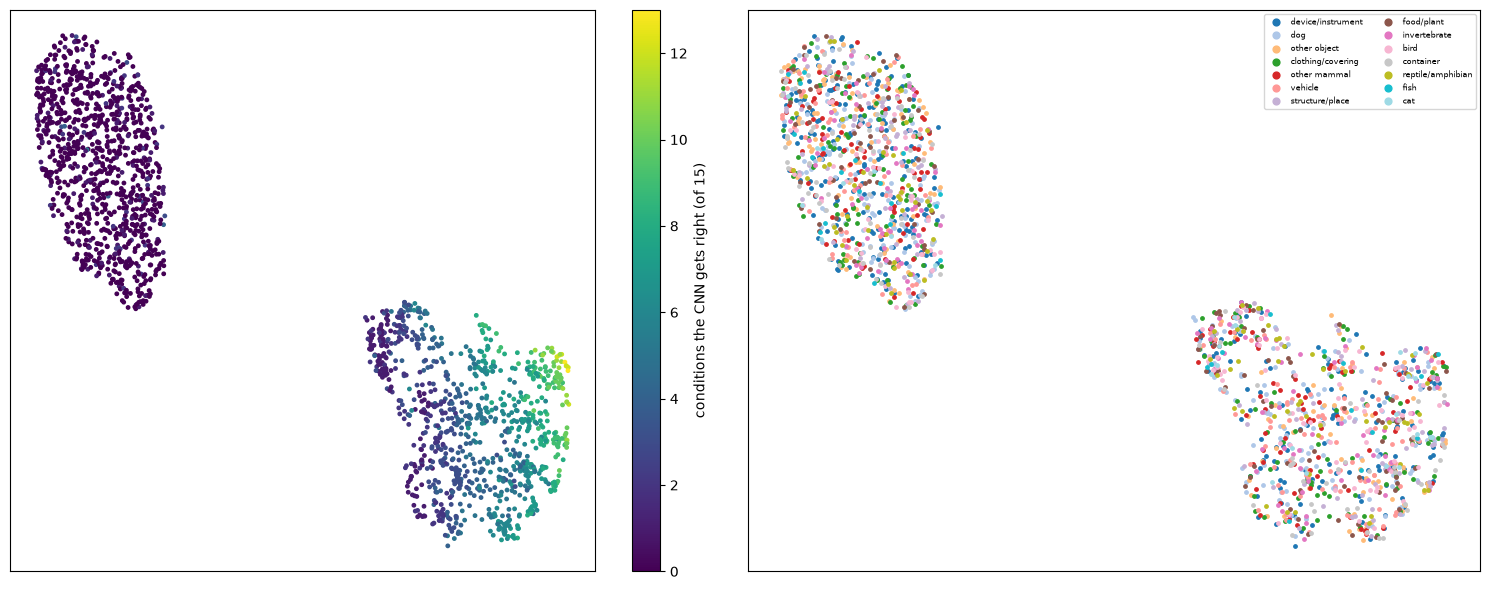

In [5]:
import umap
P = []
for m in ("cnn_ok", "snn_ok", "agree"):
    P.append(W.pivot_table(index="image_id", columns=["corruption", "severity"], values=m, aggfunc="first"))
PROF = pd.concat(P, axis=1).astype(int)
meta = W.drop_duplicates("image_id").set_index("image_id").loc[PROF.index]
UP = {"n_neighbors": 30, "min_dist": 0.2, "metric": "hamming", "random_state": 0}
Z = umap.UMAP(**UP).fit_transform(PROF.values.astype(bool))
print("UMAP", UP, "| images:", len(PROF), "| dims:", PROF.shape[1])
n_ok = PROF.iloc[:, :15].sum(1)
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
sc = axs[0].scatter(Z[:, 0], Z[:, 1], c=n_ok, cmap="viridis", s=6)
fig.colorbar(sc, ax=axs[0], label="conditions the CNN gets right (of 15)")
cmap = plt.cm.tab20(np.linspace(0, 1, len(GROUPS)))
for g, col in zip(GROUPS, cmap):
    k = (meta.group == g).values
    axs[1].scatter(Z[k, 0], Z[k, 1], s=6, color=col, label=g)
axs[1].legend(fontsize=6, markerscale=2, ncol=2)
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Does a group sit in its own region? kNN group purity in profile space (15 neighbours, Hamming) against the purity expected by chance, per group.

In [6]:
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=16, metric="hamming").fit(PROF.values)
_, ix = nn.kneighbors(PROF.values)
g = meta.group.to_numpy(dtype=object)
pur = (g[ix[:, 1:]] == g[:, None]).mean(1)
chance = pd.Series(g).value_counts(normalize=True)
R = pd.DataFrame({"group": g, "purity": pur}).groupby("group").purity.mean().to_frame()
R["chance"] = chance.reindex(R.index)
R["ratio"] = R.purity / R.chance
R.sort_values("ratio", ascending=False).round(3)

,purity,chance,ratio
group,,,
cat,0.036,0.013,2.761
fish,0.025,0.016,1.562
other object,0.127,0.093,1.360
container,0.065,0.055,1.179
vehicle,0.081,0.072,1.125
device/instrument,0.178,0.162,1.101
food/plant,0.068,0.063,1.075
dog,0.138,0.130,1.065
other mammal,0.079,0.075,1.055


## Which groups survive longest?
Mean number of conditions right (of 15) per group, both models.

In [7]:
S = meta.assign(cnn=PROF.iloc[:, :15].sum(1).values, snn=PROF.iloc[:, 15:30].sum(1).values)
S.groupby("group")[["cnn", "snn"]].agg(["mean", "count"]).round(2).sort_values(("cnn", "mean"), ascending=False)

cnn         snn      
                   mean count  mean count
group                                    
cat                3.92    26  4.08    26
structure/place    3.23   134  3.11   134
bird               2.98   118  3.08   118
vehicle            2.88   144  2.73   144
reptile/amphibian  2.57    88  2.69    88
invertebrate       2.54   122  2.66   122
food/plant         2.43   126  2.53   126
clothing/covering  2.41   180  2.48   180
other object       2.40   186  2.47   186
fish               2.38    32  2.19    32
other mammal       2.26   150  2.27   150
dog                2.15   260  2.22   260
device/instrument  2.14   324  2.11   324
container          2.09   110  1.99   110

## Findings (02 per image)

Run: `results_card/`, 2000 images. Behaviour profile = right/wrong for both models in 15
conditions plus agreement (45 binary values). UMAP parameters are printed in the notebook.

1. **The same images break at the same step (H6, mostly supported).** Among images at least
   one model gets right at severity 1, CNN and SNN stop being right at the same severity for 58 %
   (fog, n = 824), 66 % (noise, n = 668) and 66 % (contrast, n = 856). The off-diagonal is
   symmetric: neither model lasts longer systematically (sign tests p = 0.42 / 0.17 / 0.09).
   Contrast leans slightly to the SNN (161 vs 131 images), which matches the contrast-3 gap
   in 01.
2. **Recoveries are rare but real.** 2–13 % of images are right again at a higher severity
   after a miss. Most are under fog (CNN 9.6 %, SNN 13.1 %), whose random fog pattern differs
   per severity.
3. **Projection: one big split, no group structure.** The map separates 804 images *both*
   models never get right in any condition (40 %) from the rest. Inside the rest, the gradient
   is simply "how many conditions are right". Group purity of the 15 nearest neighbours is at
   chance level for every group (ratio 0.94–1.36), except cat (2.8×, but only 26 images). The
   object category does not predict how an image degrades (H5 not supported).
4. **Surviving longest:** cat (3.9–4.1 of 15 conditions right), structure/place (3.1–3.2),
   bird (3.0–3.1). Last: container (2.0–2.1), device/instrument (2.1). The CNN and SNN means
   per group are within 0.2 of each other for every group.

Limits: only 2 images per class, so group means rest on 26–324 images; no image features, so
the projection shows *behaviour*, not appearance.
